In [8]:
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from PIL import Image

ROOT = Path("..")
RAW_DIR = ROOT / "data" / "raw" / "plantwild"
CONFIG_PATH = ROOT / "configs" / "classes.yml"

with CONFIG_PATH.open() as file:
    class_config = yaml.safe_load(file)

selected_crops = set(class_config["crops"])
project_classes = class_config["classes"]
class_by_name = {name: name for name in project_classes}
source_labels = sorted(path.name for path in RAW_DIR.iterdir() if path.is_dir())

print(f"PlantWild directory: {RAW_DIR.resolve()}")
print(f"Total source labels: {len(source_labels)}")
print(f"Selected crops: {', '.join(sorted(selected_crops))}")
print(f"Project classes in scope: {len(project_classes)}")

PlantWild directory: /home/idrislabidi/vscode/plant-disease-project/data/raw/plantwild
Total source labels: 115
Selected crops: apple, corn, tomato
Project classes in scope: 18


## Scope and label mapping

PlantWild contains many crops, but this project evaluates only the crops declared in `configs/classes.yml`: apple, corn, and tomato. The source labels are mapped to the nearest project class only when the correspondence is explicit. Labels without a project-class match remain excluded from downstream analysis.

In [9]:
# Explicit PlantWild aliases; target values are resolved from the project class list.
source_to_target = {
    "apple black rot": "apple__black_rot",
    "apple rust": "apple__cedar_apple_rust",
    "apple scab": "apple__apple_scab",
    "corn gray leaf spot": "corn__gray_leaf_spot",
    "corn northern leaf blight": "corn__northern_leaf_blight",
    "corn rust": "corn__common_rust",
    "tomato bacterial leaf spot": "tomato__bacterial_spot",
    "tomato early blight": "tomato__early_blight",
    "tomato late blight": "tomato__late_blight",
    "tomato leaf mold": "tomato__leaf_mold",
    "tomato mosaic virus": "tomato__mosaic_virus",
    "tomato septoria leaf spot": "tomato__septoria_leaf_spot",
    "tomato yellow leaf curl virus": "tomato__yellow_leaf_curl_virus",
}

assert set(source_to_target).issubset(source_labels)
assert set(source_to_target.values()).issubset(project_classes)

selected_source_labels = sorted(source_to_target)
excluded_selected_like = sorted(
    label for label in source_labels
    if label.split(" ", 1)[0] in selected_crops and label not in source_to_target
)

print("Mapped source labels:", len(selected_source_labels))
print("Mapped project classes:", len(set(source_to_target.values())))
print("Excluded apple/corn/tomato labels:", excluded_selected_like)
print("Out-of-scope source labels:", len(source_labels) - len(selected_source_labels) - len(excluded_selected_like))

Mapped source labels: 13
Mapped project classes: 13
Excluded apple/corn/tomato labels: ['apple mosaic virus', 'corn smut']
Out-of-scope source labels: 100


## Image inventory and coverage

PlantWild counts below cover only labels mapped to the configured apple, corn, and tomato classes.

In [20]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
records = []
read_errors = []

for source_label, target_class in source_to_target.items():
    label_dir = RAW_DIR / source_label
    for image_path in sorted(label_dir.iterdir()):
        if not image_path.is_file() or image_path.suffix.lower() not in image_extensions:
            continue
        record = {
            "path": image_path,
            "source_label": source_label,
            "class": target_class,
            "crop": target_class.split("__", 1)[0],
            "file_name": image_path.name,
        }
        try:
            with Image.open(image_path) as image:
                record.update({"width": image.width, "height": image.height, "mode": image.mode, "format": image.format})
        except (OSError, ValueError) as error:
            read_errors.append({"path": str(image_path), "error": str(error)})
            continue
        records.append(record)

images_df = pd.DataFrame(records)
expected_classes = set(project_classes)
observed_classes = set(images_df["class"])
missing_classes = sorted(expected_classes - observed_classes)

print(f"Readable selected images: {len(images_df):,}")
print(f"Unreadable selected images: {len(read_errors)}")
print(f"Missing project classes in PlantWild: {missing_classes}")
images_df.head()

Readable selected images: 1,796
Unreadable selected images: 0
Missing project classes in PlantWild: ['apple__healthy', 'corn__healthy', 'tomato__healthy', 'tomato__spider_mites', 'tomato__target_spot']


,path,source_label,class,crop,file_name,width,height,mode,format
0,../data/raw/plantwild/apple black rot/apple_bl...,apple black rot,apple__black_rot,apple,apple_black_rot_1.jpg,640,480,RGB,JPEG
1,../data/raw/plantwild/apple black rot/apple_bl...,apple black rot,apple__black_rot,apple,apple_black_rot_11.jpg,1080,755,RGB,JPEG
2,../data/raw/plantwild/apple black rot/apple_bl...,apple black rot,apple__black_rot,apple,apple_black_rot_12.jpg,1280,719,RGB,JPEG
3,../data/raw/plantwild/apple black rot/apple_bl...,apple black rot,apple__black_rot,apple,apple_black_rot_143.jpg,268,172,RGB,JPEG
4,../data/raw/plantwild/apple black rot/apple_bl...,apple black rot,apple__black_rot,apple,apple_black_rot_144.jpg,293,220,RGB,JPEG


,crop,class,images,share_within_crop
0,apple,apple__apple_scab,258,0.537500
2,apple,apple__cedar_apple_rust,139,0.289583
1,apple,apple__black_rot,83,0.172917
3,corn,corn__common_rust,177,0.427536
5,corn,corn__northern_leaf_blight,130,0.314010
4,corn,corn__gray_leaf_spot,107,0.258454
7,tomato,tomato__early_blight,187,0.207317
8,tomato,tomato__late_blight,163,0.180710
9,tomato,tomato__leaf_mold,156,0.172949
11,tomato,tomato__septoria_leaf_spot,130,0.144124


,crop,images,share
0,apple,480,0.267261
1,corn,414,0.230512
2,tomato,902,0.502227


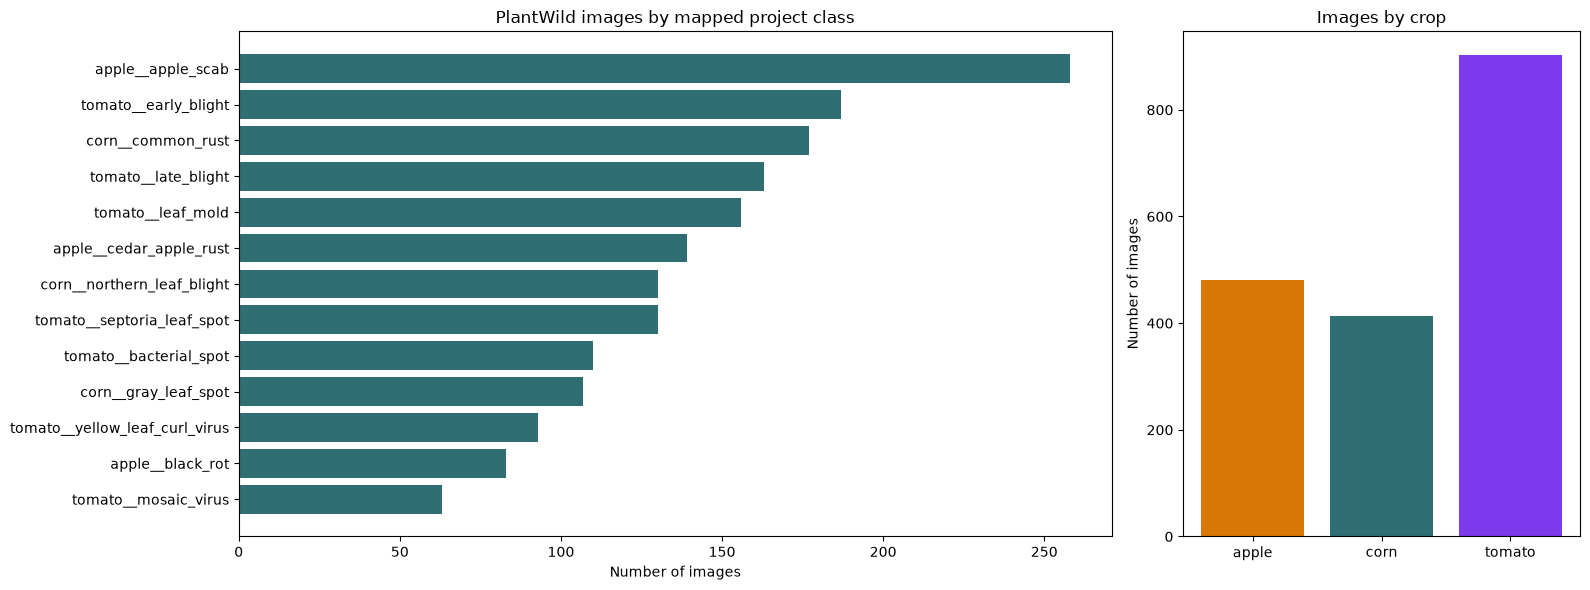

In [21]:
## Counts by class and crop

class_counts = (images_df.groupby(["crop", "class"], as_index=False).size().rename(columns={"size": "images"}))
class_counts["share_within_crop"] = class_counts["images"] / class_counts.groupby("crop")["images"].transform("sum")
crop_counts = (images_df.groupby("crop", as_index=False).size().rename(columns={"size": "images"}))
crop_counts["share"] = crop_counts["images"] / crop_counts["images"].sum()
display(class_counts.sort_values(["crop", "images"], ascending=[True, False]))
display(crop_counts)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2.2, 1]})
class_plot = class_counts.sort_values("images")
axes[0].barh(class_plot["class"], class_plot["images"], color="#2f6f73")
axes[0].set_title("PlantWild images by mapped project class")
axes[0].set_xlabel("Number of images")
axes[0].set_ylabel("")
axes[1].bar(crop_counts["crop"], crop_counts["images"], color=["#d97706", "#2f6f73", "#7c3aed"])
axes[1].set_title("Images by crop")
axes[1].set_ylabel("Number of images")
fig.tight_layout()
plt.show()

,metric,value
0,images with non-RGB mode,0
1,images with shorter side < 64 px,0
2,unique image sizes,1183
3,minimum width,68
4,minimum height,76
5,median width,640
6,median height,500


,crop,mode,images
0,apple,RGB,480
1,corn,RGB,414
2,tomato,RGB,902


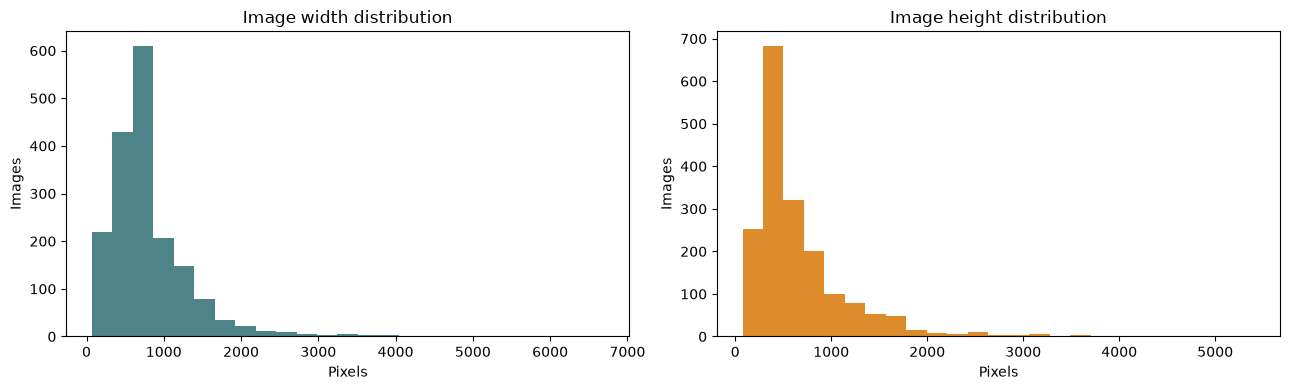

In [22]:
## Image quality and dimensions

quality_summary = pd.DataFrame({
    "metric": ["images with non-RGB mode", "images with shorter side < 64 px", "unique image sizes", "minimum width", "minimum height", "median width", "median height"],
    "value": [int((images_df["mode"] != "RGB").sum()), int((images_df[["width", "height"]].min(axis=1) < 64).sum()), int(images_df[["width", "height"]].drop_duplicates().shape[0]), int(images_df["width"].min()), int(images_df["height"].min()), int(images_df["width"].median()), int(images_df["height"].median())],
})
display(quality_summary)
display(images_df.groupby(["crop", "mode"], as_index=False).size().rename(columns={"size": "images"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(images_df["width"], bins=25, color="#2f6f73", alpha=0.85)
axes[0].set_title("Image width distribution")
axes[0].set_xlabel("Pixels")
axes[0].set_ylabel("Images")
axes[1].hist(images_df["height"], bins=25, color="#d97706", alpha=0.85)
axes[1].set_title("Image height distribution")
axes[1].set_xlabel("Pixels")
axes[1].set_ylabel("Images")
fig.tight_layout()
plt.show()

In [23]:
## Exact duplicates

import hashlib
hash_to_paths = {}
for image_path in images_df["path"]:
    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    hash_to_paths.setdefault(digest, []).append(image_path)
duplicate_groups = [paths for paths in hash_to_paths.values() if len(paths) > 1]
duplicate_images = sum(len(paths) - 1 for paths in duplicate_groups)
print(f"Unique file hashes: {len(hash_to_paths):,}")
print(f"Exact duplicate groups: {len(duplicate_groups)}")
print(f"Images beyond the first in duplicate groups: {duplicate_images}")

Unique file hashes: 1,783
Exact duplicate groups: 13
Images beyond the first in duplicate groups: 13


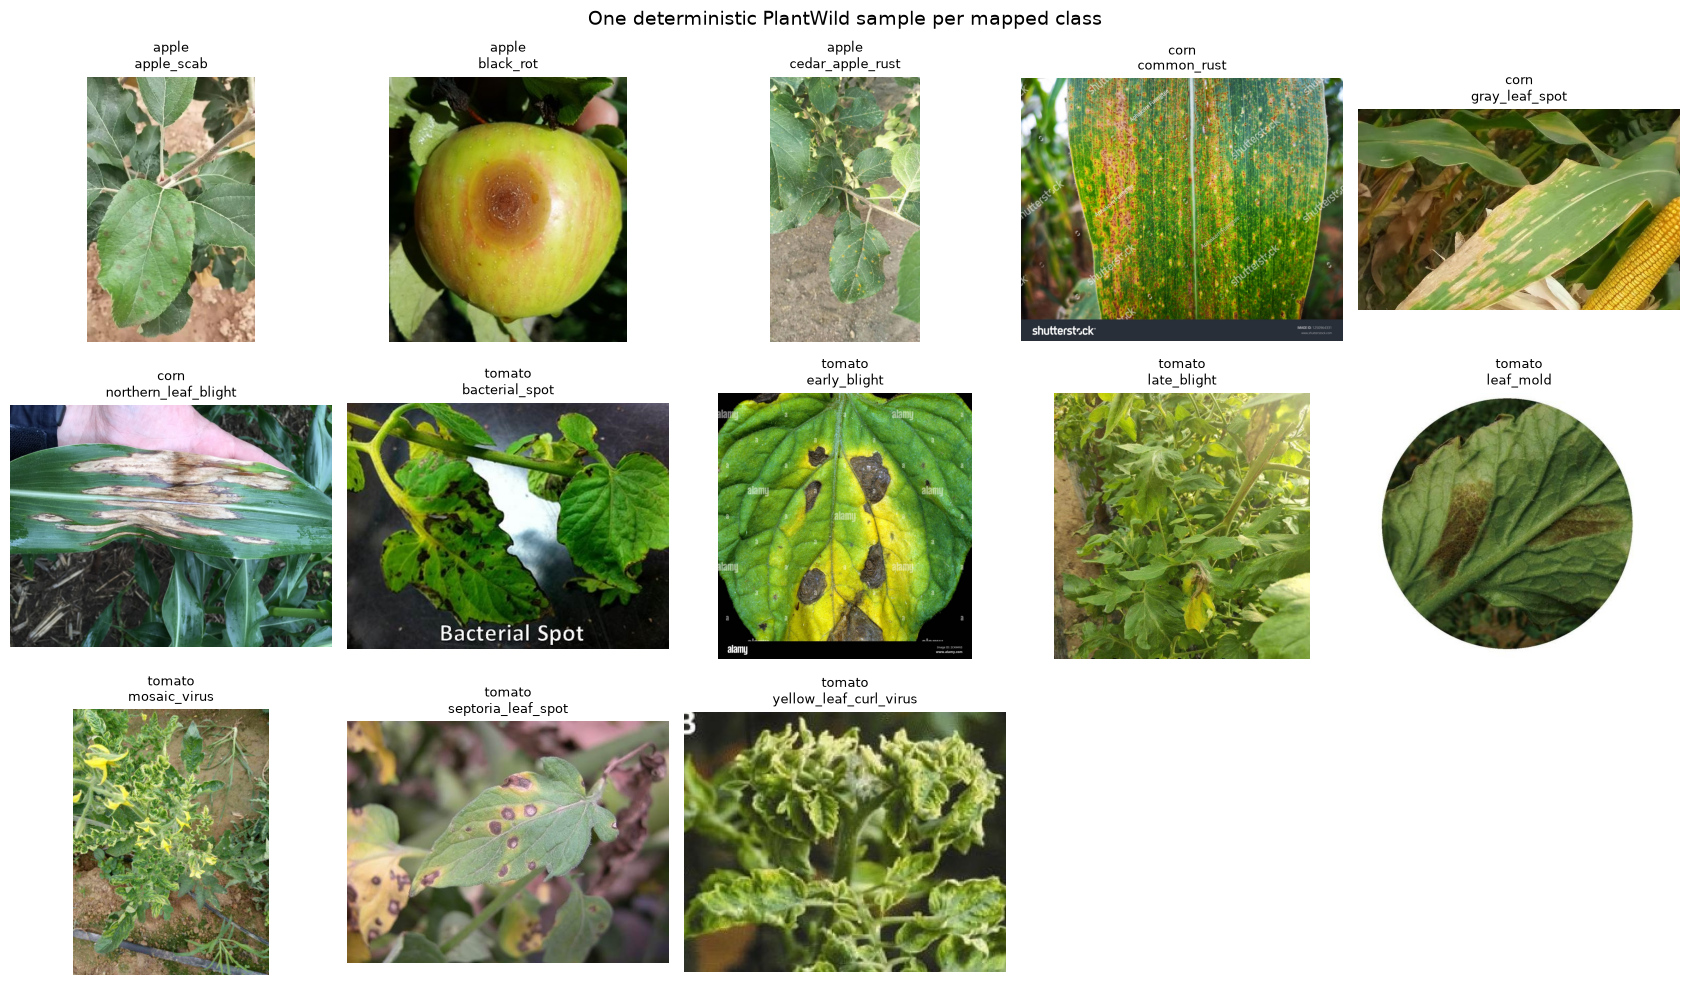

In [24]:
## Representative samples

sample_rows = images_df.groupby("class", as_index=False).sample(n=1, random_state=42).reset_index(drop=True)
fig, axes = plt.subplots(3, 5, figsize=(17, 10))
for axis, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    with Image.open(row["path"]) as image:
        axis.imshow(image)
    axis.set_title(row["class"].replace("__", "\n"), fontsize=9)
    axis.axis("off")
for axis in axes.flat[len(sample_rows):]:
    axis.axis("off")
fig.suptitle("One deterministic PlantWild sample per mapped class", fontsize=14)
fig.tight_layout()
plt.show()

In [26]:
## EDA conclusions

largest_class = class_counts.loc[class_counts["images"].idxmax()]
smallest_class = class_counts.loc[class_counts["images"].idxmin()]
print(f"PlantWild contributes {len(images_df):,} readable images across {len(observed_classes)} of {len(project_classes)} configured classes.")
print(f"The largest mapped class is {largest_class['class']} ({largest_class['images']:,} images); the smallest is {smallest_class['class']} ({smallest_class['images']:,} images).")
print("Crop totals: " + ", ".join(f"{row.crop}={row.images:,}" for row in crop_counts.itertuples()) + ".")
print(f"Quality checks found {len(read_errors)} unreadable files, {int((images_df['mode'] != 'RGB').sum())} non-RGB images, and {duplicate_images} exact duplicate files.")
print("The missing classes are " + ", ".join(missing_classes) + ". Do not use PlantWild as a standalone evaluation set for those classes.")

PlantWild contributes 1,796 readable images across 13 of 18 configured classes.
The largest mapped class is apple__apple_scab (258 images); the smallest is tomato__mosaic_virus (63 images).
Crop totals: apple=480, corn=414, tomato=902.
Quality checks found 0 unreadable files, 0 non-RGB images, and 13 exact duplicate files.
The missing classes are apple__healthy, corn__healthy, tomato__healthy, tomato__spider_mites, tomato__target_spot. Do not use PlantWild as a standalone evaluation set for those classes.
